# 07 · Diseño de rescate con barrera de seguridad

> **Lugar en el argumento:** Track 2. Convierte una idea terapéutica en una cadena auditable:
> qué debe ser cierto, qué evidencia existe y qué medición puede matar la hipótesis.
>
> **Salida principal:** matriz de ocho puentes × diez dimensiones y diseño del siguiente
> experimento. No es eficacia clínica, recomendación ni prueba de seguridad.

> Se nomina una **cartera experimental**: dos hipótesis farmacológicas (azitromicina, arimoclomol) y un comparador adversarial (sirolimus), para **discriminación preclínica**. **No se nomina un ganador terapéutico ni se recomienda administrar ningún compuesto.**
>
> Una versión anterior de esta cabecera decía «NO HAY NOMINACIÓN DE FÁRMACO», y luego el
> propio notebook nominaba tres brazos. Las dos frases podían pasar por prudentes por
> separado; juntas eran una contradicción.
>
> Toda la evidencia citada tiene identificador **verificado en el proyecto**. Donde falta
> evidencia se escribe *hueco*, no una cita plausible.

## Pregunta

**¿Existe un mecanismo terapéutico plausible, falsable y seguro para este paciente?**

## La corrección que reorganiza todo

Agrupar la evidencia bajo «proteostasis» metía en la misma caja dos intervenciones con lógica
terapéutica distinta y **consecuencias oncológicas potencialmente opuestas**:

| | T2-A · aguas arriba | T2-B · aguas abajo |
|---|---|---|
| Cadena | La variante desestabilizaría BUBR1; subir su abundancia mejoraría el checkpoint | La célula ya aneuploide sufre estrés; subir HSP la haría tolerarlo mejor |
| Efecto buscado | **menos** células aneuploides nuevas | las que existen **viven mejor** |
| Riesgo | podría reducir CIN | podría aumentar la supervivencia de células inestables |

En un niño que ya tuvo un rabdomiosarcoma, **esa diferencia lo es todo**.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Inventario", "Lo que un hueco no significa")

## Resultado primario 1 · la matriz de evidencia

Un mapa de cajas y flechas explica **la idea**. No enseña **qué evidencia existe**. Esta matriz
cruza los ocho puentes contra diez dimensiones de evidencia y dice, celda a celda, qué hay.

Se lee de **`research/track2_evidence.tsv`**, un fichero versionado: cada celda es una fila con
su fuente. **No hay ni una caja escrita dentro del código de la figura**, que es exactamente el
defecto que esta pasada venía a corregir: una caja no se puede auditar ni comparar entre
versiones; una fila sí.

Regla dura del fichero: **ninguna celda distinta de `ABSENT` puede quedarse sin fuente**, y el
notebook lo comprueba antes de dibujar.

In [3]:
TSV = "research/track2_evidence.tsv"
raw = [l.rstrip(chr(10)).split(chr(9)) for l in io.open(TSV, encoding="utf-8")
       if not l.startswith("#") and l.strip()]
HDR, EV = raw[0], [dict(zip(raw[0], r + [""] * (len(raw[0]) - len(r)))) for r in raw[1:]]

DIMS = ["paciente", "mva_humana", "celulas_aneuploides", "otro_contexto",
        "perturbacion_genetica", "perturbacion_farmacologica",
        "abundancia_bubr1", "proteostasis", "cin", "supervivencia_clonogenica"]
BR = sorted({int(e["puente"]) for e in EV})
TIT = {int(e["puente"]): e["titulo"] for e in EV}
RUTA = {int(e["puente"]): e["ruta"] for e in EV}
CELL = {(int(e["puente"]), e["dimension"]): e for e in EV}

# La regla dura, comprobada aqui y no solo escrita en el fichero
huerf = [e for e in EV if e["clase"] != "ABSENT" and not e["fuente"].strip()]
assert not huerf, f"celdas sin fuente: {[(e['puente'], e['dimension']) for e in huerf]}"
assert len(EV) == len(BR) * len(DIMS), f"la matriz no esta completa: {len(EV)} filas"

import collections as _c
cnt = _c.Counter(e["clase"] for e in EV)
print(f"  {TSV}  ·  {len(EV)} celdas = {len(BR)} puentes x {len(DIMS)} dimensiones")
print(f"  toda celda distinta de ABSENT lleva fuente: OK")
print()
for k in ("DIRECT", "GENETIC", "NEAR", "CONTRADICTORY", "ABSENT"):
    print(f"    {k:<16}{cnt.get(k,0):>4}  ({100*cnt.get(k,0)/len(EV):.0f} %)")
print()
fuentes = sorted({e["fuente"] for e in EV if e["fuente"].strip()})
print(f"  fuentes distintas citadas: {len(fuentes)}")
for f in fuentes:
    print(f"    {f}")

  research/track2_evidence.tsv  ·  80 celdas = 8 puentes x 10 dimensiones
  toda celda distinta de ABSENT lleva fuente: OK

    DIRECT             9  (11 %)
    GENETIC            2  (2 %)
    NEAR               5  (6 %)
    CONTRADICTORY      3  (4 %)
    ABSENT            61  (76 %)

  fuentes distintas citadas: 7
    DOI 10.1007/s00439-008-0572-y
    DOI 10.1038/s41467-025-60857-4
    PMID 20516114
    PMID 34481829
    PMID 34481829 · DOI 10.1016/j.jlr.2021.100114
    docs/EVIDENCE.md
    src/structure/ (EXP-010, EXP-011)


### Figura principal 1 · ocho puentes × diez dimensiones de evidencia

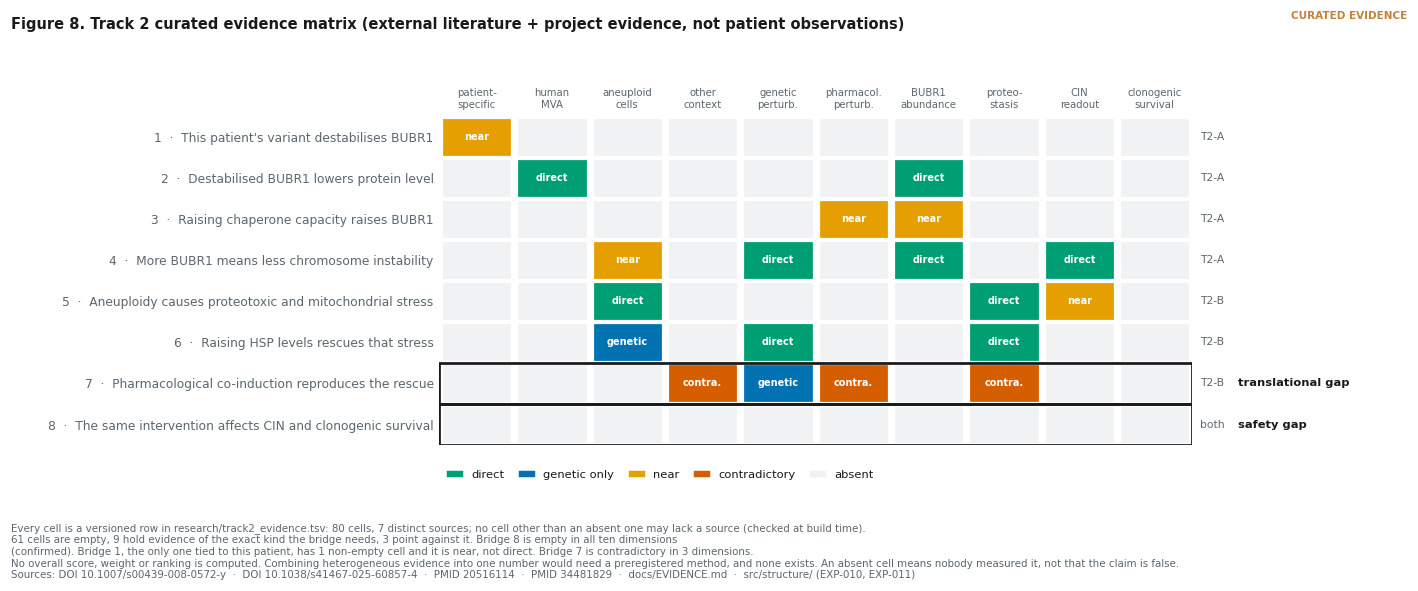

> **Figura principal 1 · matriz de evidencia curada de Track 2**  
> `EXP-016 · EXP-016b` · figure class `CURATED_EVIDENCE`, figura cientifica · evidence origin `EXTERNAL`  
> *Inventario.* que evidencia existe de verdad para cada puente. De las 80 celdas, 61 estan vacias, 9 tienen evidencia del tipo exacto que el puente necesita y 3 apuntan EN CONTRA, sobre 7 fuentes distintas. La fila 8 esta vacia en las diez dimensiones, que es el hueco de seguridad, y la fila 1, la unica que conecta con este paciente, solo tiene una celda no vacia y es NEAR, no DIRECT. El puente 7 es el hueco TRASLACIONAL.  
> **Lo que un hueco no significa.** que Track 2 sea valido ni invalido. Es un inventario de evidencia curada (literatura externa mas evidencia del proyecto), no observaciones experimentales del paciente, y por eso no se etiqueta simplemente DATA. Una celda ABSENT dice que nadie lo ha medido, no que sea falso. Y NO se calcula ninguna puntuacion global: combinar evidencia heterogenea en un numero exigiria un metodo preregistrado que no existe.  
> datos: `research/track2_evidence.tsv · 80 celdas versionadas, cada una con fuente` · libreria: `matplotlib` · procedencia: `figures/pub/fig07_track2_evidence_matrix.svg + .png 300 dpi`

In [4]:
from src.figures import fig07_evidence as FE

fig, _st = FE.build(EV)
_n_abs = _st["counts"].get("ABSENT", 0)
_n_dir = _st["counts"].get("DIRECT", 0)
_n_con = _st["counts"].get("CONTRADICTORY", 0)
fl.pub(fig, "Figura principal 1 · matriz de evidencia curada de Track 2",
       "EXP-016 · EXP-016b", "EXTERNAL", "CURATED_EVIDENCE",
       f"que evidencia existe de verdad para cada puente. De las {len(EV)} celdas, "
       f"{_n_abs} estan vacias, {_n_dir} tienen evidencia del tipo exacto que el puente "
       f"necesita y {_n_con} apuntan EN CONTRA, sobre {len(_st['sources'])} fuentes "
       f"distintas. La fila 8 esta vacia en las diez dimensiones, que es el hueco de seguridad, y "
       f"la fila 1, la unica que conecta con este paciente, solo tiene una celda no vacia y "
       f"es NEAR, no DIRECT. El puente 7 es el hueco TRASLACIONAL.",
       "que Track 2 sea valido ni invalido. Es un inventario de evidencia curada (literatura "
       "externa mas evidencia del proyecto), no observaciones experimentales del paciente, y "
       "por eso no se etiqueta simplemente DATA. Una celda ABSENT dice que nadie lo ha "
       "medido, no que sea falso. Y NO se calcula ninguna puntuacion global: combinar "
       "evidencia heterogenea en un numero exigiria un metodo preregistrado que no existe.",
       source="research/track2_evidence.tsv · 80 celdas versionadas, cada una con fuente",
       lib="matplotlib", slug="fig07_track2_evidence_matrix")

## Resultado primario 2 · los ocho puentes, como mapa

Toda afirmación declara **qué puente sostiene**. La evidencia de un puente **no vale** para
otro.

In [5]:
BRIDGES = [
 (1, "variante de ESTE paciente\n-> inestabilidad de BUBR1", "T2-A", "hueco",
     "solo inferencia estructural y conservacion"),
 (2, "inestabilidad -> menos proteina", "T2-A", "ok",
     "niveles bajos en pacientes, incluso con missense, pero de otros alelos"),
 (3, "subir chaperonas -> SUBIR BUBR1", "T2-A", "contra",
     "la evidencia va en direccion CONTRARIA: inhibir HSP90 lo hunde"),
 (4, "mas BUBR1 -> menos CIN", "T2-A", "ok",
     "gradiente 8,5-77 %; aneuploidia clara < ~50 % (DOI 10.1007/s00439-008-0572-y)"),
 (5, "aneuploidia -> estres proteotoxico", "T2-B", "ok",
     "p62 con precursores mitocondriales, ADNmt bajo (DOI 10.1038/s41467-025-60857-4)"),
 (6, "subir HSP (GENETICO) -> rescate", "T2-B", "parcial",
     "rescata, PERO el efecto dependio del cariotipo: una linea no respondio"),
 (7, "coinduccion FARMACOLOGICA\n-> el mismo rescate", "T2-B", "contra",
     "cero evidencia directa; contraejemplo verificado (PMID 34481829)"),
 (8, "la intervencion -> efecto sobre CIN\ny supervivencia clonogenica", "ambas", "vacio",
     "NUNCA MEDIDO en ninguna direccion"),
]
COL = {"ok": fl.ALIVE, "parcial": fl.OPEN, "hueco": fl.DEAD, "contra": fl.DEAD,
       "vacio": fl.VOID}
for n, t, r, st, note in BRIDGES:
    print(f"  {n}. [{r:<6}] {st.upper():<8} {t.splitlines()[0]:<44} {note[:52]}")

  1. [T2-A  ] HUECO    variante de ESTE paciente                    solo inferencia estructural y conservacion
  2. [T2-A  ] OK       inestabilidad -> menos proteina              niveles bajos en pacientes, incluso con missense, pe
  3. [T2-A  ] CONTRA   subir chaperonas -> SUBIR BUBR1              la evidencia va en direccion CONTRARIA: inhibir HSP9
  4. [T2-A  ] OK       mas BUBR1 -> menos CIN                       gradiente 8,5-77 %; aneuploidia clara < ~50 % (DOI 1
  5. [T2-B  ] OK       aneuploidia -> estres proteotoxico           p62 con precursores mitocondriales, ADNmt bajo (DOI 
  6. [T2-B  ] PARCIAL  subir HSP (GENETICO) -> rescate              rescata, PERO el efecto dependio del cariotipo: una 
  7. [T2-B  ] CONTRA   coinduccion FARMACOLOGICA                    cero evidencia directa; contraejemplo verificado (PM
  8. [ambas ] VACIO    la intervencion -> efecto sobre CIN          NUNCA MEDIDO en ninguna direccion


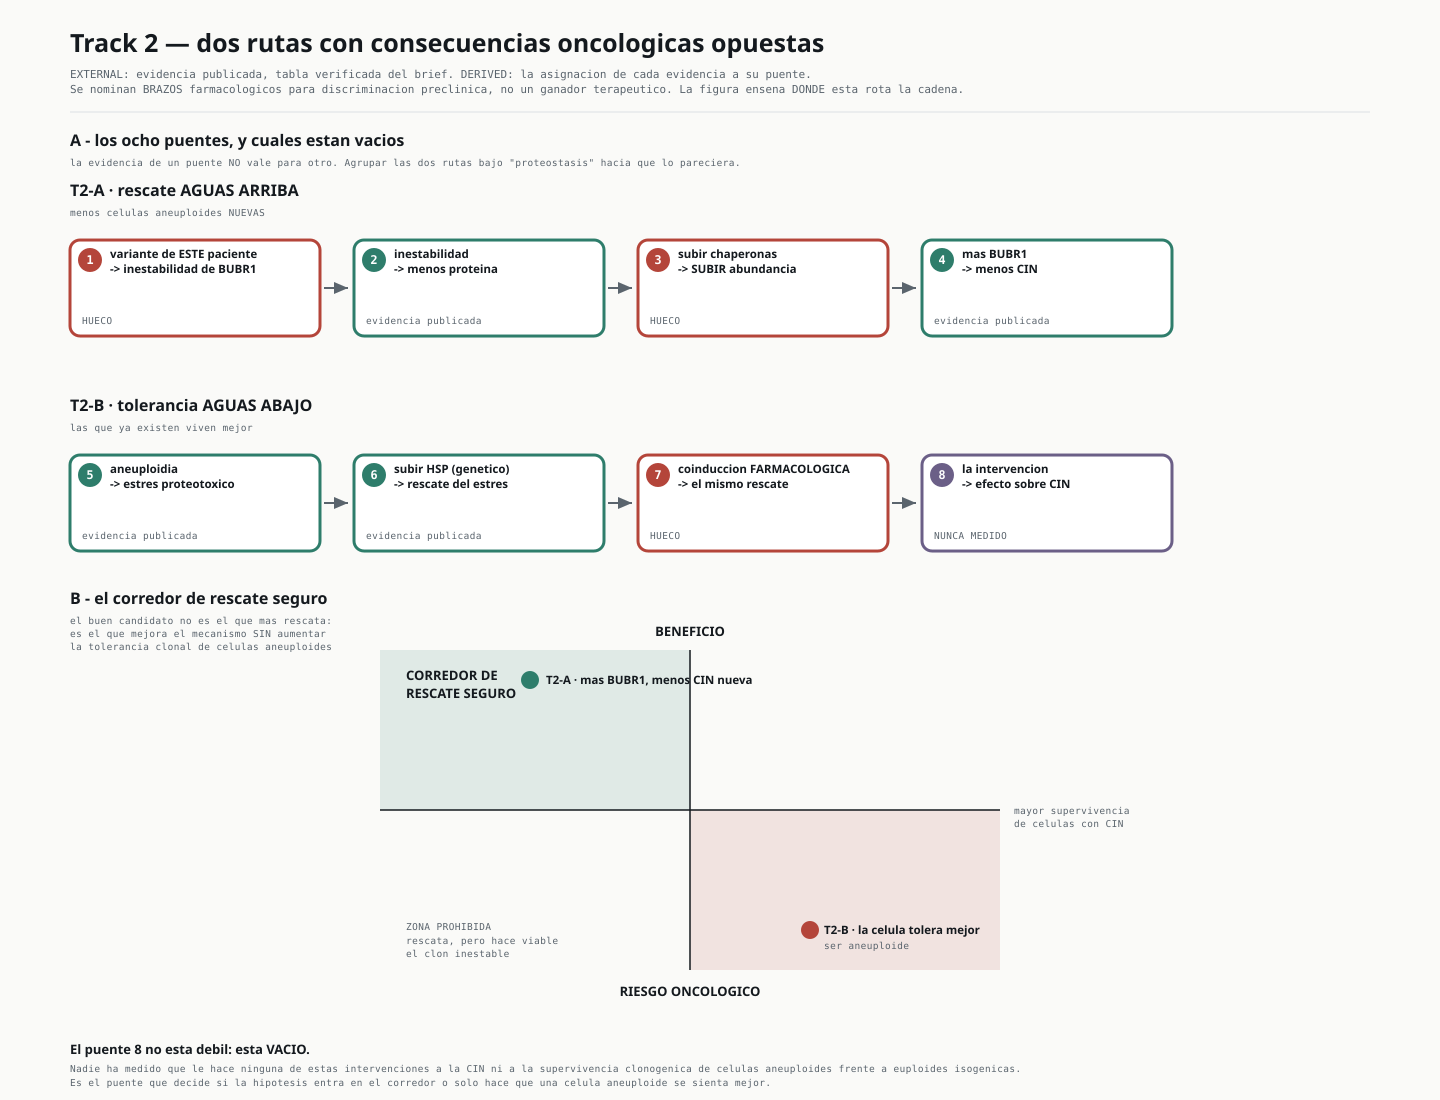

> **Figura principal 2 · los ocho puentes y el corredor**  
> `EXP-016` · figure class `SYNTHESIS`, no es un dato: synthesis · evidence origin `EXTERNAL+DERIVED`  
> *Inventario.* en rojo los puentes rotos, en morado el que nunca se midio. El panel B situa las dos rutas en el plano beneficio/riesgo: T2-A puede caer en el corredor; T2-B, por construccion, empuja hacia el eje de riesgo.  
> **Lo que un hueco no significa.** que T2-B este muerta ni que T2-A funcione. Ningun puente roto se ha cerrado como NEGATIVE: estan UNRESOLVED, que es distinto.  
> libreria: `SVG` · procedencia: `src/make_fig10.py genera fig10_track2_bridges.svg, sha256[:12]=b47759c2b351`

In [6]:
fl.svg("figures/fig10_track2_bridges.svg",
       "Figura principal 2 · los ocho puentes y el corredor",
       "EXP-016", "EXTERNAL+DERIVED", "SYNTHESIS",
       "en rojo los puentes rotos, en morado el que nunca se midio. El panel B situa las dos "
       "rutas en el plano beneficio/riesgo: T2-A puede caer en el corredor; T2-B, por "
       "construccion, empuja hacia el eje de riesgo.",
       "que T2-B este muerta ni que T2-A funcione. Ningun puente roto se ha cerrado como "
       "NEGATIVE: estan UNRESOLVED, que es distinto.",
       generator="src/make_fig10.py")

## Resultado primario 3 · el puente 7, que es el corazón falsable

Búsqueda acotada con clasificación fijada de antemano:

| Clase | Encontrado |
|---|---|
| `DIRECT`: células aneuploides, coinductor y rescate | Ninguna |
| `NEAR`: coinducción en otro contexto proteotóxico | Sí, pero **no se admite como sustituto** |
| `GENETIC`: solo sobreexpresión | Sí, y es toda la evidencia del puente 6 |
| **CONTRADICTORY** | **Dos, verificadas** |

**El contraejemplo (PMID 34481829).** En fibroblastos NPC1, la sobreexpresión de HSP70 redujo
el almacenamiento de colesterol; el coinductor **no lo reprodujo** hasta 500 µM, y el detalle
que más pesa: **no llegó a inducir HSP70**.

**La tensión (PMID 25205676).** En aneuploides humanos la inducción de la respuesta de choque
térmico está **al 50–60 %** del control. Lo que rescató fue **HSF1 constitutivamente activo**.

> **Formulación congelada:**
>
> *HSF1 impairment makes the pathway both mechanistically relevant and pharmacologically
> uncertain. Genetic augmentation can bypass the deficit; whether a stress-dependent
> pharmacological co-inducer can amplify the impaired endogenous response sufficiently
> remains unresolved.*

## Robustez · «Try to Kill It», y por qué es la mejor diapositiva

**La señal de eficacia y la señal de riesgo oncológico son la misma medición.**

Si una intervención rescata preferentemente a las células **más** aneuploides, eso es a la vez
la prueba de que el mecanismo es el propuesto **y** la prueba de que se está mejorando la
supervivencia clonogénica de células genómicamente inestables.

## Evidencia contradictoria, declarada

| Afirmación | Contraevidencia |
|---|---|
| Subir HSP es terapéutico | Un coinductor **no fue efectivo** en ELA |
| Genético ≈ farmacológico | **PMID 34481829**: el genético rescató, el farmacológico no, y no indujo HSP70 |
| El rescate genético es universal | Dependió del **cariotipo**; una línea aneuploide no respondió |
| Ayudar a la célula aneuploide es bueno | **Es la definición oncológica de un paso temprano de tumorigénesis** |


## Resultado primario 4 · la cartera experimental, no un ganador

Hasta aquí el notebook ha dicho qué evidencia **falta**. Esta sección dice qué se **haría con
eso**, que es lo que pide el entregable oficial de Track 2: proponer fármaco o fármacos
aprobados sustentados por el mecanismo.

La respuesta honesta no es un nombre. Es una **cartera de tres brazos con tres papeles
distintos**, más tres controles, formalizada en `research/track2_candidates.tsv` y validada
por `src/verify.py`. No lleva puntuación global, ranking ni ganador, por la misma razón que
no lo lleva la matriz de puentes: combinar evidencia heterogénea en un número exige un método
preregistrado que no existe.

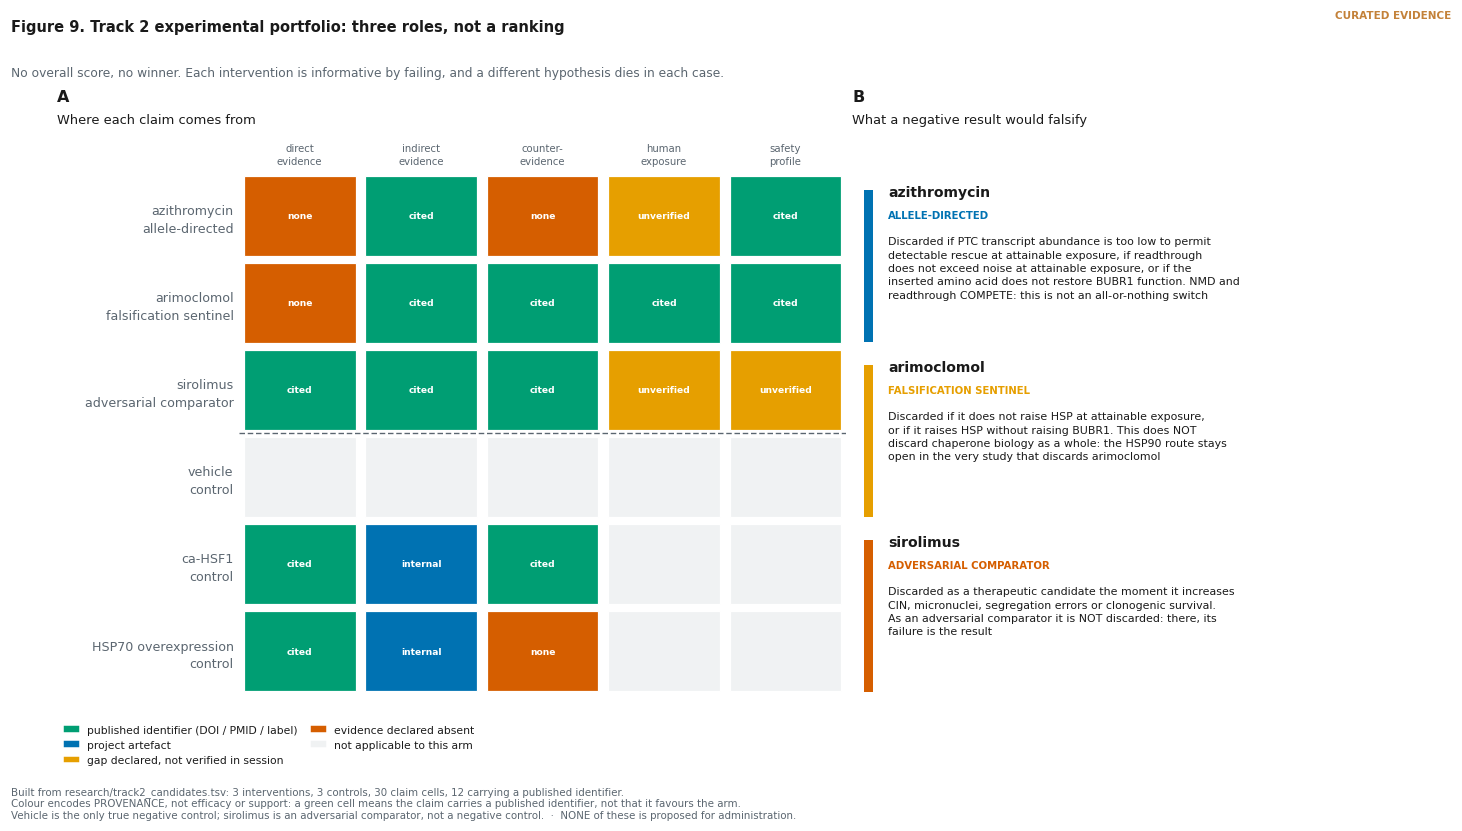

> **Figura principal 3 · cartera experimental de Track 2**  
> `EXP-016 · EXP-016b` · figure class `CURATED_EVIDENCE`, figura cientifica · evidence origin `EXTERNAL`  
> *Inventario.* que los tres brazos no compiten por un primer puesto: ocupan papeles distintos y cada uno informa AL FALLAR. De las 30 celdas de afirmacion, 12 llevan identificador publicado y el resto son ausencias o huecos DECLARADOS. Azitromicina es el unico brazo dirigido al alelo truncante de ESTE paciente y no tiene ninguna evidencia directa. Arimoclomol es el unico con contraevidencia verificada, y por eso vale como centinela. Sirolimus es el unico con evidencia farmacologica directa, y esa evidencia es PARCIALMENTE NEGATIVA en el desenlace que importa.  
> **Lo que un hueco no significa.** que ninguno de los tres sirva, ni que alguno deba administrarse. NO es una nominacion terapeutica: es el instrumento para decidir cual seria el PRIMER experimento preclinico. Ningun candidato de esta tabla se propone para administracion a ningun paciente, y este proyecto no emite recomendaciones clinicas.  
> datos: `research/track2_candidates.tsv · 6 filas versionadas, cada afirmacion con identificador o hueco declarado` · libreria: `matplotlib` · procedencia: `figures/pub/fig08_track2_portfolio.svg + .png 300 dpi`

In [7]:
from src.figures import fig08_portfolio as FP

_rows = FP.read()
fig, _pt = FP.build(_rows)
_cells = len(_rows) * len(FP.CLAIMS)
fl.pub(fig, "Figura principal 3 · cartera experimental de Track 2",
       "EXP-016 · EXP-016b", "EXTERNAL", "CURATED_EVIDENCE",
       f"que los tres brazos no compiten por un primer puesto: ocupan papeles distintos y "
       f"cada uno informa AL FALLAR. De las {_cells} celdas de afirmacion, {_pt['cited']} "
       f"llevan identificador publicado y el resto son ausencias o huecos DECLARADOS. "
       f"Azitromicina es el unico brazo dirigido al alelo truncante de ESTE paciente y no "
       f"tiene ninguna evidencia directa. Arimoclomol es el unico con contraevidencia "
       f"verificada, y por eso vale como centinela. Sirolimus es el unico con evidencia "
       f"farmacologica directa, y esa evidencia es PARCIALMENTE NEGATIVA en el desenlace "
       f"que importa.",
       "que ninguno de los tres sirva, ni que alguno deba administrarse. NO es una "
       "nominacion terapeutica: es el instrumento para decidir cual seria el PRIMER "
       "experimento preclinico. Ningun candidato de esta tabla se propone para "
       "administracion a ningun paciente, y este proyecto no emite recomendaciones clinicas.",
       source="research/track2_candidates.tsv · 6 filas versionadas, cada afirmacion con "
              "identificador o hueco declarado",
       lib="matplotlib", slug="fig08_track2_portfolio")

### Los tres papeles, y por qué el fallo de cada uno enseña algo distinto

| Brazo | Papel | Por qué está | Qué muere si falla |
|---|---|---|---|
| **azitromicina** | `ALLELE` · dirigido al alelo | Es el **único** brazo que ataca el alelo truncante de este paciente, por lectura a través del codón de parada prematuro. El contexto tira en dos direcciones: la parada es **UGA**, en general permisiva, pero lleva **A en +4**, menos favorable que C o U. Y lo decisivo: el **contexto extendido** impide predecir la respuesta sin medirla (DOI 10.1038/s41467-024-46703-z) | La hipótesis de readthrough **para este alelo**. No toca el resto de Track 2 |
| **arimoclomol** | `SENTINEL` · centinela de falsación | Es el único con **contraevidencia verificada**: en fibroblastos NPC1 el rescate genético funcionó y él no, sin llegar a inducir HSP70 (PMID 34481829). Está para **resolver el puente 7**, no para ganar | La traducción farmacológica *arimoclomol → coinducción de HSP* **en ese sistema**. **NO** cae el brazo de chaperonas: la vía HSP90 sigue abierta en el mismo trabajo que lo descarta |
| **sirolimus** | `ADVERSARIAL` · comparador de seguridad | Es el único con evidencia farmacológica **directa** (rapamicina a 40 µM en larvas, DOI 10.1038/s41467-026-70521-0), y esa evidencia ya enseña el problema: rescató el número de neuroblastos aneuploides **sin** restaurar células Pros+ ni el tamaño cerebral | Nada, y ese es justo el punto. **Como comparador adversarial su fallo es el resultado**: prueba el límite del Safe Rescue Corridor |

Y los tres controles, que no son decorativos:

| Control | Qué separa |
|---|---|
| **vehículo** | El cero real de cada lectura. Es el **único control negativo verdadero**; ningún compuesto activo lo es |
| **ca-HSF1** | Control positivo **contextual**, en células aneuploides isogénicas humanas. Sin él, un negativo de arimoclomol es ininterpretable: no se sabría si falló el fármaco o la biología. **Su rescate dependió del cariotipo**, y eso se declara |
| **HSP70 sobreexpresión** | Comparador mecanístico secundario. **No** es el control positivo contextual: su evidencia viene de fibroblastos NPC1, no de células aneuploides |

## Decisión

| | |
|---|---|
| **Clase superviviente principal** | Modulación de proteostasis y chaperonas, entre las seis evaluadas |
| **T2-A, aguas arriba** | `UNRESOLVED`, bloqueada por los puentes 1 y 3 |
| **T2-B, aguas abajo** | `UNRESOLVED`, bloqueada por los puentes 7 y 8 |
| **Propuesta de Track 2** | **Una cartera de 3 intervenciones y 3 controles para un primer experimento preclínico**, con el papel de cada brazo declarado y su regla de descarte escrita por adelantado |
| **Lo que SÍ se nomina** | **Tres brazos farmacológicos para discriminación preclínica**: dos hipótesis candidatas (azitromicina, arimoclomol) y un comparador adversarial (sirolimus), cada uno con su regla de descarte escrita por adelantado |
| **Lo que NO se nomina** | Un ganador terapéutico, y ninguna recomendación clínica. Ninguno de los tres reúne las cinco condiciones de la compuerta, y el puente 8 está vacío para los tres |
| Proteasoma · poda clonal | **NEGATIVE** |
| Estabilización por acetilación · senolíticos | **PARKED** |

**La distinción que sostiene todo lo anterior.** Nominamos **brazos farmacológicos para
discriminación preclínica**, no un ganador terapéutico ni una recomendación clínica.
Proponer un experimento no es nominar un tratamiento. La compuerta del fármaco exige las cinco: estatus aprobado · proximidad
mecanística a un puente nombrado · evidencia **de ese** puente · predicción de rescate
falsable · contra-test explícito de CIN/tumor. **Hoy ninguna candidata las reúne**, y la
cartera existe precisamente para averiguar cuál podría.

> **Ninguno de estos compuestos se propone para administración a ningún paciente.** Este
> proyecto produce una hipótesis falsable para investigación preclínica y **no emite
> recomendaciones clínicas** (`CLAUDE.md`, Regla Dura 3).

### Qué NO demuestra este notebook

Que la clase sea la correcta · que exista un fármaco que sirva · que rescatar sea seguro. Y
tampoco que se haya barrido el espacio terapéutico completo: se evaluaron **seis clases
elegidas desde la cadena mecanística del caso**.

### Falsificador

El experimento de abajo, con sus desenlaces preescritos, y las tres reglas de descarte de la
cartera. Cada brazo lleva escrito **por adelantado** qué resultado lo mata, y dos de los
cuatro desenlaces del experimento matan la hipótesis. Eso es lo que la hace falsable.

### Next Best Experiment

Par isogénico aneuploide/euploide ± coinductor candidato, con **control positivo genético**
(HSF1 constitutivamente activo) y **lectura obligatoria de si el fármaco induce HSP**, porque
el contraejemplo enseña que puede **no** inducir, y sin medirlo no se sabe si falló el
fármaco o la hipótesis. Midiendo a la vez CIN y supervivencia clonogénica.